## **Malaria Cell Image Classification Using Convolutional Neural Networks and Apache Spark**


###**Problem Statement and Objective**
We propose to classify microscopic red blood cell images as parasitized or uninfected using a convolutional neural network (CNN). The project will combine Apache Spark-based image preparation with TensorFlow/Keras model development, then compare a baseline CNN against an optimized version. The main challenges are variable image dimensions, preventing overfitting, and determining which training choices improve classification performance.

###**Dataset**
We will use the Malaria dataset containing 27,558 labeled RGB cell images: 13,779 parasitized and 13,779 uninfected. Images have varying dimensions and will be standardized before training.
Dataset link: https://www.tensorflow.org/datasets/catalog/malaria


## **Part 1: Exploratory Data Analysis and Spark Preprocessing**

**Team Member: Sandra**

This section focuses on exploring and preparing the Malaria Cell Images dataset using PySpark. It includes examining class distributions, image dimensions, and data quality, followed by image resizing and normalization. We will also compare different Spark configurations to evaluate preprocessing performance.

In [1]:

!pip -q install pyspark


In [1]:

# Common Library Imports

# File handling
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from io import BytesIO
import json

# Numerical operations and visualization
import numpy as np
import matplotlib.pyplot as plt

# Image processing
from PIL import Image

# Apache Spark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col, regexp_extract, when, udf

from pyspark.sql.types import (
    BooleanType,
    BinaryType,
    IntegerType,
    StringType,
    FloatType,
    ArrayType,
    StructType,
    StructField
)

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import BackupAndRestore
from tensorflow.keras.callbacks import ModelCheckpoint

# Data splitting and model evaluation
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Other utilities
import time
import os

print("All libraries imported successfully.")


All libraries imported successfully.


In [3]:
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)
print("GPU count:", len(gpus))


Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU count: 1


In [2]:

spark = (
    SparkSession.builder
    .appName("Malaria_Image_Preprocessing")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/26 08:28:48 WARN Utils: Your hostname, Noelles-MacBook-Air-812.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.42 instead (on interface en0)
26/11/26 08:28:48 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/26 08:28:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.1


##### This creates a pyspark configuration an session environment to process this large dataset.

### Image Loading:

In [3]:


data_folder = Path("data")

data_folder.mkdir(exist_ok=True)

url = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

zip_path = data_folder / "cell_images.zip"

if not zip_path.exists():
    urlretrieve(url, zip_path)

print(zip_path.exists())


True


#### The above code  retrieves the data online and creates a data folder for the dataset.

In [4]:

print("File size:", zip_path.stat().st_size)

with ZipFile(zip_path, "r") as zip_file:
    print("Corrupted member:", zip_file.testzip())


File size: 353452851
Corrupted member: None


### Image Extraction:

In [5]:

# Open the downloaded ZIP file
with ZipFile(zip_path, "r") as zip_file:

    # Extract all files into the data folder
    zip_file.extractall(data_folder)

print("Extraction completed successfully!")


Extraction completed successfully!


In [6]:

images_df = (
    spark.read
    .format("binaryFile")
    .option("recursiveFileLookup", "true")
    .option("pathGlobFilter", "*.png")
    .load("data/cell_images")
)

print("Total images:", images_df.count())


Total images: 27558


In [7]:

images_df = images_df.withColumn(
    "class_name",
    regexp_extract(
        col("path"),
        r"/(Parasitized|Uninfected)/",
        1
    )
)

images_df.select("path", "class_name").show(5, truncate=False)


+-------------------------------------------------------------------------------------------------------------------+-----------+
|path                                                                                                               |class_name |
+-------------------------------------------------------------------------------------------------------------------+-----------+
|file:/Users/noellehaviland/cnn_training/data/cell_images/Parasitized/C91P52ThinF_IMG_20150821_124311_cell_34.png   |Parasitized|
|file:/Users/noellehaviland/cnn_training/data/cell_images/Uninfected/C170P131ThinF_IMG_20151119_120150_cell_49.png  |Uninfected |
|file:/Users/noellehaviland/cnn_training/data/cell_images/Parasitized/C68P29N_ThinF_IMG_20150819_134625_cell_64.png |Parasitized|
|file:/Users/noellehaviland/cnn_training/data/cell_images/Parasitized/C92P53ThinF_IMG_20150821_150457_cell_252.png  |Parasitized|
|file:/Users/noellehaviland/cnn_training/data/cell_images/Parasitized/C180P141NThinF_IMG_2

In [8]:

images_df = images_df.withColumn(
    "label",
    when(col("class_name") == "Parasitized", 1)
    .when(col("class_name") == "Uninfected", 0)
)

images_df.select("class_name", "label").show(10)


+-----------+-----+
| class_name|label|
+-----------+-----+
|Parasitized|    1|
| Uninfected|    0|
|Parasitized|    1|
|Parasitized|    1|
|Parasitized|    1|
|Parasitized|    1|
|Parasitized|    1|
|Parasitized|    1|
|Parasitized|    1|
|Parasitized|    1|
+-----------+-----+
only showing top 10 rows


In [9]:

images_df.select(
    F.count("*").alias("total_images"),

    F.sum(
        F.when(F.col("content").isNull(), 1).otherwise(0)
    ).alias("missing_images"),

    F.sum(
        F.when(F.length("content") == 0, 1).otherwise(0)
    ).alias("empty_images"),

    F.sum(
        F.when(
            F.col("class_name").isNull() |
            (F.trim(F.col("class_name")) == ""),
            1
        ).otherwise(0)
    ).alias("missing_labels")
).show()

+------------+--------------+------------+--------------+
|total_images|missing_images|empty_images|missing_labels|
+------------+--------------+------------+--------------+
|       27558|             0|           0|             0|
+------------+--------------+------------+--------------+



##### The above code output shows that the total images tally and no row or observation is missing while importing. No misiing images or empty images



In [10]:

# Define a function to check image integrity
def check_corrupted(image_bytes):

    if image_bytes is None or len(image_bytes) == 0:
        return True

    try:
        with Image.open(BytesIO(image_bytes)) as img:
            img.verify()

        # Reopen and decode the image pixels
        with Image.open(BytesIO(image_bytes)) as img:
            img.load()

        return False

    except Exception:
        return True


# Convert the function into a Spark UDF
corruption_udf = udf(check_corrupted, BooleanType())

# Apply the function
quality_df = images_df.withColumn(
    "is_corrupted",
    corruption_udf(col("content"))
)

# Count corrupted images
quality_df.groupBy("is_corrupted").count().show()

/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/udf.py:116: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/udf.py:120: RuntimeWarning: Arrow optimization failed to enable because PyArrow or Pandas is not installed. Falling back to a non-Arrow-optimized UDF.
  warnings.warn(


+------------+-----+
|is_corrupted|count|
+------------+-----+
|       false|27558|
+------------+-----+



##### The code above shows that the image has no corrupted file and it is fit for further preprocessing and use for training.

In [11]:


# Create a fingerprint for each image
hashed_df = images_df.withColumn(
    "image_hash",
    F.sha2(F.col("content"), 256)
)

# Find repeated fingerprints
duplicate_groups = (
    hashed_df
    .filter(F.col("image_hash").isNotNull())
    .groupBy("image_hash")
    .count()
    .filter(F.col("count") > 1)
)

# Display duplicate groups
duplicate_groups.show(10, truncate=False)

# Count duplicate records beyond the first copy
duplicate_records = duplicate_groups.select(
    F.sum(F.col("count") - 1).alias("duplicate_records")
).first()["duplicate_records"]

print("Extra duplicate records:", duplicate_records or 0)

+----------+-----+
|image_hash|count|
+----------+-----+
+----------+-----+



Extra duplicate records: 0


#### The output of the above code shows no duplicate observation in the image sample dataset

### Image Class Distribution:


In [12]:

class_distribution = (
    images_df
    .groupBy("class_name", "label")
    .count()
)

class_distribution.show()


+-----------+-----+-----+
| class_name|label|count|
+-----------+-----+-----+
|Parasitized|    1|13779|
| Uninfected|    0|13779|
+-----------+-----+-----+



#####  This checks the class distribution amongst the target variables.

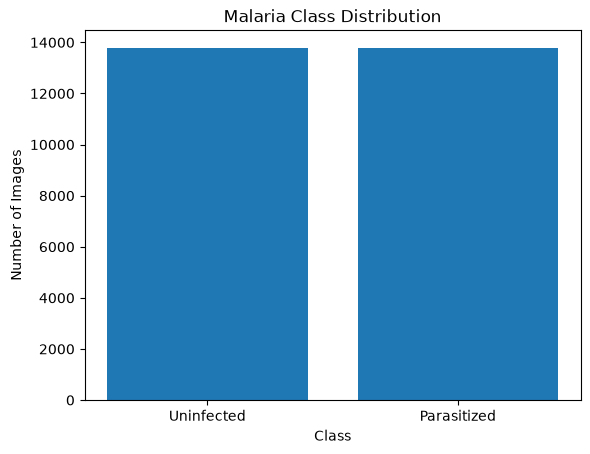

In [13]:
class_rows = class_distribution.orderBy("label").collect()

class_names = [row["class_name"] for row in class_rows]
class_counts = [row["count"] for row in class_rows]

plt.bar(class_names, class_counts)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Malaria Class Distribution")
plt.show()

In [14]:

# Retrieve the first image record from Spark
first_row = images_df.first()

# Convert binary image data into a PIL image
image = Image.open(BytesIO(first_row["content"]))

# Retrieve the image's numerical label
label = first_row["label"]

# Inspect the image
print(type(image))
print(label)
print(image.size)
print(image.mode)


<class 'PIL.PngImagePlugin.PngImageFile'>
1
(364, 340)
RGB


##### The above checks the image dimesions, channels. This shows that the image has different dimensions and has the -color channel.

In [15]:

# Define the structure of the output
image_schema = StructType([
    StructField("width", IntegerType(), True),
    StructField("height", IntegerType(), True)
])

# Create a function to extract image dimensions
def get_image_dimensions(image_bytes):
    try:
        with Image.open(BytesIO(image_bytes)) as img:
            return (img.width, img.height)
    except Exception:
        return (None, None)

# Convert the Python function into a Spark UDF
dimensions_udf = udf(get_image_dimensions, image_schema)

# Apply the function to the images
images_df = images_df.withColumn(
    "dimensions",
    dimensions_udf("content")
)

# Display the extracted dimensions
images_df.select(
    "class_name",
    "dimensions.width",
    "dimensions.height"
).show(10)


+-----------+-----+------+
| class_name|width|height|
+-----------+-----+------+
|Parasitized|  364|   340|
| Uninfected|  220|   211|
|Parasitized|  265|   346|
|Parasitized|  223|   217|
|Parasitized|  244|   304|
|Parasitized|  178|   193|
|Parasitized|  394|   241|
|Parasitized|  184|   238|
|Parasitized|  208|   382|
|Parasitized|  181|   226|
+-----------+-----+------+
only showing top 10 rows


##### The above output shows that the images of the dataset has varying sizes which woud affect the CNN model architecture process particularly the batching. As the batching requires uniformity of the image dimension or size.

### Image Statistics:

In [16]:

# Extract image widths and heights
image_dimensions = images_df.select(
    col("dimensions.width").alias("image_width"),
    col("dimensions.height").alias("image_height")
)

# Display the dimensions
image_dimensions.show(10)


+-----------+------------+
|image_width|image_height|
+-----------+------------+
|        364|         340|
|        220|         211|
|        265|         346|
|        223|         217|
|        244|         304|
|        178|         193|
|        394|         241|
|        184|         238|
|        208|         382|
|        181|         226|
+-----------+------------+
only showing top 10 rows


In [17]:

image_stats = image_dimensions.agg(
    F.min("image_width").alias("Minimum_width"),
    F.max("image_width").alias("Maximum_width"),
    F.min("image_height").alias("Minimum_height"),
    F.max("image_height").alias("Maximum_height"),
    F.round(F.avg("image_width"), 2).alias("Average_width"),
    F.round(F.avg("image_height"), 2).alias("Average_height")
)

image_stats.show()


+-------------+-------------+--------------+--------------+-------------+--------------+
|Minimum_width|Maximum_width|Minimum_height|Maximum_height|Average_width|Average_height|
+-------------+-------------+--------------+--------------+-------------+--------------+
|           46|          394|            40|           385|       132.49|        132.98|
+-------------+-------------+--------------+--------------+-------------+--------------+



##### The above output describes the image statistics, the minimum and maximum width, average width and height and the maximum, minimum height. this helps in making a decision on how to resize the image in subsequent process.

### Image Width Histogram Distribution Plot:

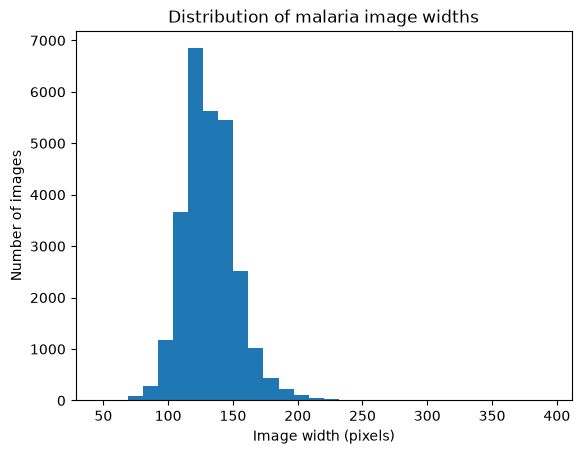

In [18]:

# Retrieve the minimum and maximum image widths
width_stats = image_dimensions.agg(
    F.min("image_width").alias("min_width"),
    F.max("image_width").alias("max_width")
)

# Create the 30-bin frequency distribution in PySpark
width_histogram = (
    image_dimensions
    .crossJoin(width_stats)
    .withColumn(
        "bin",
        F.when(
            F.col("min_width") == F.col("max_width"), 0
        ).otherwise(
            F.least(
                F.floor(
                    (F.col("image_width") - F.col("min_width"))
                    * 30 /
                    (F.col("max_width") - F.col("min_width"))
                ),
                F.lit(29)
            )
        )
    )
    .groupBy("bin")
    .count()
    .orderBy("bin")
)

# Collect only the 30 aggregated counts for plotting
bins_data = width_histogram.collect()

# Prepare the histogram coordinates
bin_numbers = [row["bin"] for row in bins_data]
frequencies = [row["count"] for row in bins_data]

# Get the width range for the x-axis
width_range = width_stats.first()
min_width = width_range["min_width"]
max_width = width_range["max_width"]

bin_size = (max_width - min_width) / 30

# Plot the histogram
plt.bar(
    [min_width + b * bin_size for b in bin_numbers],
    frequencies,
    width=bin_size,
    align="edge"
)

plt.xlabel("Image width (pixels)")
plt.ylabel("Number of images")
plt.title("Distribution of malaria image widths")
plt.show()


##### The histogram above shows the image width of the pixels. this simply means that majority of the image width falls between 120-150. and this is a unimodal histogram.With over 6,900 images of the dataset with image width of 130.

### Image Height Histogram Distribution Plot:

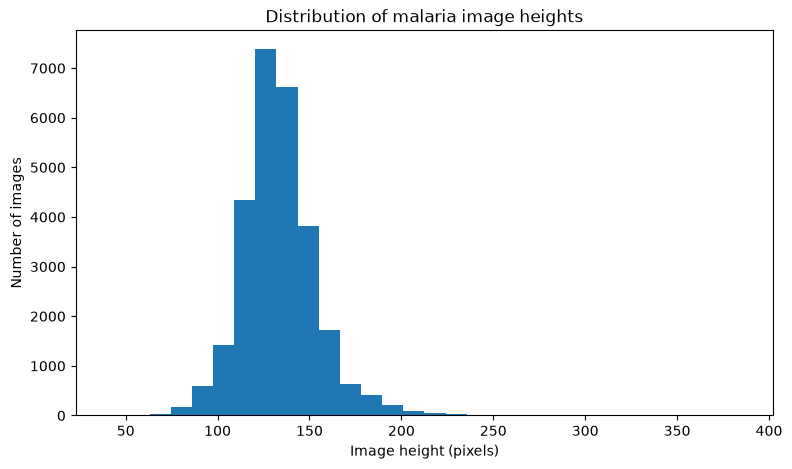

In [19]:

# Find the minimum and maximum image heights
height_stats = image_dimensions.agg(
    F.min("image_height").alias("min_height"),
    F.max("image_height").alias("max_height")
)

# Create 30 histogram bins using PySpark
height_bins = 30

height_histogram = (
    image_dimensions
    .crossJoin(height_stats)
    .withColumn(
        "bin",
        F.when(
            F.col("min_height") == F.col("max_height"), 0
        ).otherwise(
            F.least(
                F.floor(
                    (F.col("image_height") - F.col("min_height"))
                    * height_bins
                    / (F.col("max_height") - F.col("min_height"))
                ),
                F.lit(height_bins - 1)
            )
        )
    )
    .groupBy("bin")
    .agg(F.count("*").alias("frequency"))
    .orderBy("bin")
)

# Retrieve only aggregated data for visualization
height_data = height_histogram.collect()
height_range = height_stats.first()

min_height = height_range["min_height"]
max_height = height_range["max_height"]

bin_size = (max_height - min_height) / height_bins

bin_positions = [
    min_height + row["bin"] * bin_size
    for row in height_data
]

frequencies = [
    row["frequency"]
    for row in height_data
]

# Plot the image-height distribution
plt.figure(figsize=(9, 5))

plt.bar(
    bin_positions,
    frequencies,
    width=bin_size,
    align="edge"
)

plt.xlabel("Image height (pixels)")
plt.ylabel("Number of images")
plt.title("Distribution of malaria image heights")
plt.show()


##### The above histogram also shows the image height of the dataset. As the data set fall within the range of 120-140 pixels. Over 7,000 images has a pixel height of 120.

### Image Intensity Plot:

26/11/26 08:34:12 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


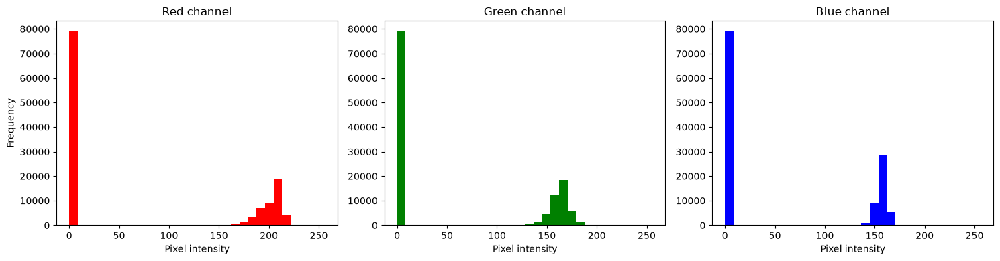

In [20]:


# 1. Start Spark
spark = SparkSession.builder \
    .appName("Malaria_RGB_Histograms") \
    .getOrCreate()

# 2. Convert the original image into RGB pixel records
pixels = np.array(image.convert("RGB"))
pixel_rows = [tuple(map(int, row)) for row in pixels.reshape(-1, 3)]

# 3. Create a PySpark DataFrame
rgb_df = spark.createDataFrame(
    pixel_rows,
    ["red", "green", "blue"]
)

# 4. Group each channel into histogram bins
bin_count = 30
bin_width = 256 / bin_count

red_hist = (
    rgb_df
    .withColumn("bin", F.floor(F.col("red") / bin_width))
    .groupBy("bin")
    .count()
    .orderBy("bin")
)

green_hist = (
    rgb_df
    .withColumn("bin", F.floor(F.col("green") / bin_width))
    .groupBy("bin")
    .count()
    .orderBy("bin")
)

blue_hist = (
    rgb_df
    .withColumn("bin", F.floor(F.col("blue") / bin_width))
    .groupBy("bin")
    .count()
    .orderBy("bin")
)

# 5. Collect only the histogram counts for plotting
red_counts = {row["bin"]: row["count"] for row in red_hist.collect()}
green_counts = {row["bin"]: row["count"] for row in green_hist.collect()}
blue_counts = {row["bin"]: row["count"] for row in blue_hist.collect()}

bin_centers = [(i + 0.5) * bin_width for i in range(bin_count)]

# 6. Plot the three RGB histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(
    bin_centers,
    [red_counts.get(i, 0) for i in range(bin_count)],
    width=bin_width,
    color="red"
)
axes[0].set_title("Red channel")
axes[0].set_xlabel("Pixel intensity")
axes[0].set_ylabel("Frequency")

axes[1].bar(
    bin_centers,
    [green_counts.get(i, 0) for i in range(bin_count)],
    width=bin_width,
    color="green"
)
axes[1].set_title("Green channel")
axes[1].set_xlabel("Pixel intensity")

axes[2].bar(
    bin_centers,
    [blue_counts.get(i, 0) for i in range(bin_count)],
    width=bin_width,
    color="blue"
)
axes[2].set_title("Blue channel")
axes[2].set_xlabel("Pixel intensity")

plt.tight_layout()
plt.show()


##### This shows the intensity of the images for each channel. This graph tell s us where majority of the pixel are. Across the Red, Green and Blue there are majority of the images with Zeros.While the Red intensity has images of 200-230. The  green channel has its brightness fall within 150- 190. Finally, the Blue channel has its brightness within 150 -170.


##### This show that majority of the images have heavy Red channel. This could be as a result of the staining materials used to differentiate the paratiszed cell and uninfected cell. So, this influenced the decision of preserving the RGB channel rather than changing it to grayscale which might conceal some key features in diffrentiating the labels.

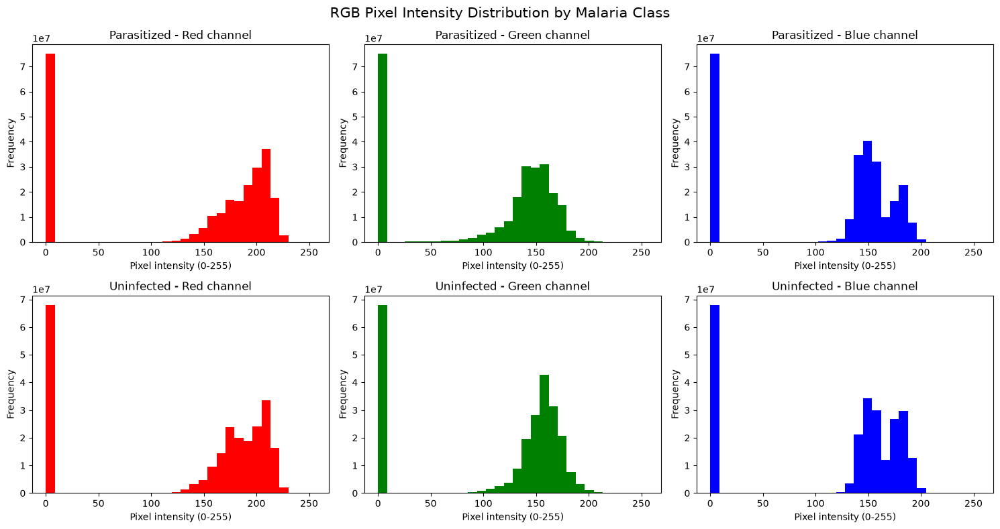

In [21]:

# STEP 1: Define histogram settings
bin_count = 30
bin_width = 256 / bin_count

# STEP 2: Define a function to calculate RGB histograms
def calculate_rgb_histograms(rows):

    for row in rows:
        class_name = row["class_name"]
        image_bytes = row["content"]

        if image_bytes is None:
            continue

        try:
            with Image.open(BytesIO(image_bytes)) as img:
                pixels = np.asarray(
                    img.convert("RGB"),
                    dtype=np.uint8
                )

            # Separate RGB channels
            for channel_index, channel_name in enumerate(
                ["red", "green", "blue"]
            ):

                channel_pixels = pixels[:, :, channel_index]

                # Count pixels in 30 bins
                counts, _ = np.histogram(
                    channel_pixels,
                    bins=bin_count,
                    range=(0, 256)
                )

                # Return aggregated counts for each bin
                for bin_index, frequency in enumerate(counts):
                    yield (
                        class_name,
                        channel_name,
                        int(bin_index),
                        int(frequency)
                    )

        except Exception:
            continue


# STEP 3: Define the output structure
histogram_schema = StructType([
    StructField("class_name", StringType(), False),
    StructField("channel", StringType(), False),
    StructField("bin", IntegerType(), False),
    StructField("frequency", IntegerType(), False)
])


# STEP 4: Process all images using Spark partitions
histogram_rdd = (
    images_df
    .select("class_name", "content")
    .rdd
    .mapPartitions(calculate_rgb_histograms)
)

histogram_df = spark.createDataFrame(
    histogram_rdd,
    schema=histogram_schema
)


# STEP 5: Combine histogram counts for each class
rgb_histograms = (
    histogram_df
    .groupBy("class_name", "channel", "bin")
    .agg(F.sum("frequency").alias("frequency"))
    .orderBy("class_name", "channel", "bin")
)


# STEP 6: Collect only aggregated histogram results
histogram_data = rgb_histograms.collect()


# STEP 7: Prepare counts for plotting
histogram_lookup = {
    (row["class_name"], row["channel"], row["bin"]):
    row["frequency"]
    for row in histogram_data
}

bin_centers = [
    (i + 0.5) * bin_width
    for i in range(bin_count)
]


# STEP 8: Plot 6 histograms
classes = ["Parasitized", "Uninfected"]
channels = ["red", "green", "blue"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for row_index, class_name in enumerate(classes):

    for col_index, channel_name in enumerate(channels):

        frequencies = [
            histogram_lookup.get(
                (class_name, channel_name, i), 0
            )
            for i in range(bin_count)
        ]

        ax = axes[row_index, col_index]

        ax.bar(
            bin_centers,
            frequencies,
            width=bin_width,
            color=channel_name
        )

        ax.set_title(
            f"{class_name} - {channel_name.capitalize()} channel"
        )
        ax.set_xlabel("Pixel intensity (0-255)")
        ax.set_ylabel("Frequency")

plt.suptitle(
    "RGB Pixel Intensity Distribution by Malaria Class",
    fontsize=15
)

plt.tight_layout()
plt.show()


#### The above histogram output shows the various pixel intensity amongst the three colors for the uninfected and parasitised cells of the images. The red component show the highest influence in the image both in infected and uninfected with green color being more in the uninfected cell.

### Image View:

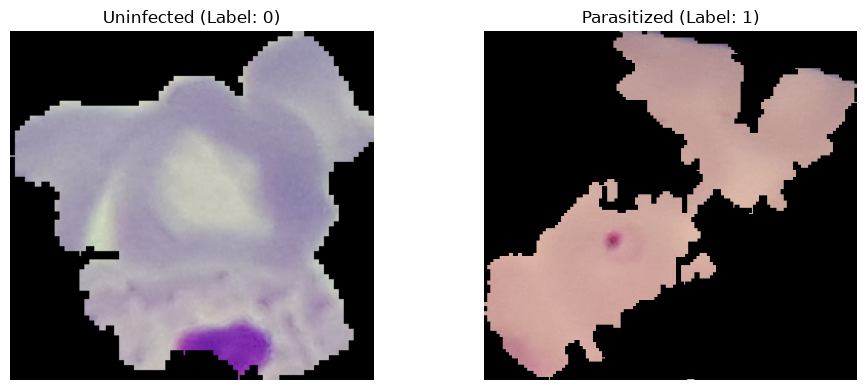

In [22]:


# STEP 1: Select one image from each class (0 and 1) from our existing Spark DataFrame
selected_rows = (
    images_df
    .groupBy("label")
    .agg(F.first("content").alias("content"), F.first("class_name").alias("class_name"))
    .orderBy("label")
    .collect()
)

# STEP 2: Create two plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# STEP 3: Display the selected images
for plot_index, row in enumerate(selected_rows):
    # Load the image from binary content
    image = Image.open(BytesIO(row["content"]))
    class_name = row["class_name"]

    axes[plot_index].imshow(image)
    axes[plot_index].set_title(f"{class_name} (Label: {row['label']})")
    axes[plot_index].axis("off")

plt.tight_layout()
plt.show()

### Image Resizing:

In [23]:

# STEP 1: Define the function to resize images
def resize_image(image_bytes):

    if image_bytes is None:
        return None

    with Image.open(BytesIO(image_bytes)) as img:

        # Convert the image to RGB
        img = img.convert("RGB")

        # Resize the image to 128 x 128
        resized_image = img.resize(
            (128, 128),
            Image.Resampling.LANCZOS
        )

        # Convert resized image back to bytes
        output = BytesIO()
        resized_image.save(output, format="PNG")

        return output.getvalue()


# STEP 2: Convert the resizing function into a Spark UDF
resize_udf = udf(resize_image, BinaryType())


# STEP 3: Apply resizing to all images
resized_df = images_df.withColumn(
    "resized_content",
    resize_udf(col("content"))
)


# STEP 4: Define a function to check image dimensions
def get_resized_dimensions(image_bytes):

    if image_bytes is None:
        return (None, None)

    with Image.open(BytesIO(image_bytes)) as img:
        return (img.width, img.height)


# STEP 5: Define the dimension output schema
dimension_schema = StructType([
    StructField("width", IntegerType(), True),
    StructField("height", IntegerType(), True)
])


# STEP 6: Convert dimension function into a Spark UDF
dimension_udf = udf(
    get_resized_dimensions,
    dimension_schema
)


# STEP 7: Add the actual dimensions to the DataFrame
resized_df = resized_df.withColumn(
    "resized_dimensions",
    dimension_udf(col("resized_content"))
)


# STEP 8: Display the resized image dimensions
resized_df.select(
    "class_name",
    "resized_dimensions.width",
    "resized_dimensions.height"
).show(5)


+-----------+-----+------+
| class_name|width|height|
+-----------+-----+------+
|Parasitized|  128|   128|
| Uninfected|  128|   128|
|Parasitized|  128|   128|
|Parasitized|  128|   128|
|Parasitized|  128|   128|
+-----------+-----+------+
only showing top 5 rows


### Image Scaling:

In [24]:

# 1. Define a function to rescale an image
def rescale_image(image_bytes):

    if image_bytes is None:
        return None

    with Image.open(BytesIO(image_bytes)) as img:
        pixels = np.asarray(img.convert("RGB"), dtype=np.float32)

    # Scale pixel values from 0-255 to 0-1
    scaled_pixels = pixels / 255.0

    # Flatten the array for Spark storage
    return scaled_pixels.ravel().tolist()


# 2. Convert the Python function into a Spark UDF
rescale_udf = udf(
    rescale_image,
    ArrayType(FloatType())
)


# 3. Apply the UDF to the resized images
scaled_df = resized_df.withColumn(
    "scaled_pixels",
    rescale_udf(col("resized_content"))
)

# 4. Inspect a few rescaled pixel values
scaled_df.select("class_name", "scaled_pixels").show(
    2, truncate=100
)


+-----------+----------------------------------------------------------------------------------------------------+
| class_name|                                                                                       scaled_pixels|
+-----------+----------------------------------------------------------------------------------------------------+
|Parasitized|[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0...|
| Uninfected|[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0...|
+-----------+----------------------------------------------------------------------------------------------------+
only showing top 2 rows


Traceback (most recent call last):
  File "/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 262, in manager
    code = worker(sock, authenticated)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 95, in worker
    outfile.flush()
BrokenPipeError: [Errno 32] Broken pipe


In [25]:

scaled_df.select(
    "class_name",
    F.array_min("scaled_pixels").alias("minimum_pixel"),
    F.array_max("scaled_pixels").alias("maximum_pixel")
).show(5)

+-----------+-------------+-------------+
| class_name|minimum_pixel|maximum_pixel|
+-----------+-------------+-------------+
|Parasitized|          0.0|   0.95686275|
| Uninfected|          0.0|    0.9647059|
|Parasitized|          0.0|          1.0|
|Parasitized|          0.0|          1.0|
|Parasitized|          0.0|   0.88235295|
+-----------+-------------+-------------+
only showing top 5 rows


Traceback (most recent call last):
  File "/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 262, in manager
    code = worker(sock, authenticated)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 95, in worker
    outfile.flush()
BrokenPipeError: [Errno 32] Broken pipe


##### The above output is just to investigate proper scaling of the image pixels.

## **Part 2: CNN Development and Training (Data Splitting, Augmentation, and Baseline CNN)**

**Team Member: Suha**

This section focuses on developing and training the baseline CNN model using TensorFlow/Keras. It includes splitting the dataset into training, validation, and testing sets, applying image augmentation to the training data, and designing the CNN architecture. We will also train the model and analyze training and validation curves to assess its performance and identify potential overfitting.

In [26]:
#Test spark session before starting

print("Spark version:", spark.version)
print("Spark test count:", spark.range(5).count())

Spark version: 4.2.1
Spark test count: 5



### Preprocessed Data Verification

Before splitting the dataset, we will check that Sandra's preprocessed DataFrame contains the required image paths and class labels. This will confirm that the data is accessible and ready for the next stage without loading all the image pixel values.


In [27]:
# Use Sandra's final DataFrame
# to avoid long execution time, select only metadata, not the large pixel arrays

split_metadata = scaled_df.select("path", "class_name", "label")

print("Columns:", split_metadata.columns)
split_metadata.show(5, truncate=False)

Columns: ['path', 'class_name', 'label']
+-------------------------------------------------------------------------------------------------------------------+-----------+-----+
|path                                                                                                               |class_name |label|
+-------------------------------------------------------------------------------------------------------------------+-----------+-----+
|file:/Users/noellehaviland/cnn_training/data/cell_images/Parasitized/C91P52ThinF_IMG_20150821_124311_cell_34.png   |Parasitized|1    |
|file:/Users/noellehaviland/cnn_training/data/cell_images/Uninfected/C170P131ThinF_IMG_20151119_120150_cell_49.png  |Uninfected |0    |
|file:/Users/noellehaviland/cnn_training/data/cell_images/Parasitized/C68P29N_ThinF_IMG_20150819_134625_cell_64.png |Parasitized|1    |
|file:/Users/noellehaviland/cnn_training/data/cell_images/Parasitized/C92P53ThinF_IMG_20150821_150457_cell_252.png  |Parasitized|1    |
|file:/


The output confirms that the preprocessed DataFrame contains the required columns: image path, class name, and numerical label. The labels are consistent with our classification setup, where Parasitized = 1 and Uninfected = 0. We can use this information to create the training, validation, and testing subsets without loading the image pixel arrays at this stage.



### Stratified Data Splitting (70/15/15)

We will divide the dataset into 70% training, 15% validation, and 15% testing using stratified sampling to maintain the class distribution across all three subsets. A fixed random seed (42) will be used to make the split reproducible. The same partitions will be used for baseline training and model optimization, while the test set will be reserved for the final evaluation.


In [28]:
SEED = 42

# Collect only image paths and labels (not pixel arrays)
records = split_metadata.select("path", "label").collect()

image_paths = np.array([row["path"] for row in records])
labels = np.array([row["label"] for row in records], dtype=np.int32)

# First split: 70% training, 30% remaining
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# Second split: 15% validation, 15% testing
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

# Print class distributions
for name, y in [
    ("Training", train_labels),
    ("Validation", val_labels),
    ("Testing", test_labels)
]:
    print(
        f"{name}: {len(y)} images | "
        f"Parasitized: {np.sum(y == 1)} | "
        f"Uninfected: {np.sum(y == 0)}"
    )

# Verify no overlap between partitions
assert set(train_paths).isdisjoint(val_paths)
assert set(train_paths).isdisjoint(test_paths)
assert set(val_paths).isdisjoint(test_paths)

print("\nStratified splitting completed successfully.")

Training: 19290 images | Parasitized: 9645 | Uninfected: 9645
Validation: 4134 images | Parasitized: 2067 | Uninfected: 2067
Testing: 4134 images | Parasitized: 2067 | Uninfected: 2067

Stratified splitting completed successfully.




The dataset was successfully divided into 70% training (19,290 images), 15% validation (4,134 images), and 15% testing (4,134 images). Stratified sampling maintained an equal distribution of parasitized and uninfected cells in all three subsets. We also verified that no image paths overlap between the subsets. A fixed random seed ensures reproducibility, and the same partitions will be used for subsequent model optimization and evaluation.




### Checking for Potential Data Leakage

Although the stratified split maintains balanced class distributions and prevents the same image path from appearing in multiple subsets, different cell images may originate from the same blood smear or source image. To investigate potential data leakage, we will extract the original image-group identifiers from the filenames and check whether any groups appear across the training, validation, and testing sets.


In [29]:

# Extract original smear/image group identifier
def get_image_group(path):
    filename = Path(path).name
    return filename.rsplit("_cell_", 1)[0]

train_groups = {get_image_group(p) for p in train_paths}
val_groups = {get_image_group(p) for p in val_paths}
test_groups = {get_image_group(p) for p in test_paths}

print("Training / Validation shared groups:",
      len(train_groups & val_groups))

print("Training / Testing shared groups:",
      len(train_groups & test_groups))

print("Validation / Testing shared groups:",
      len(val_groups & test_groups))


Training / Validation shared groups: 1262
Training / Testing shared groups: 1267
Validation / Testing shared groups: 1140



The results show substantial overlap between image groups across the three subsets:

- Training and Validation: 1,267 shared groups
- Training and Testing: 1,269 shared groups
- Validation and Testing: 1,149 shared groups

Although no identical file paths were shared, these results indicate that related cell images may appear in different subsets. This could lead to overly optimistic model performance because the CNN might learn characteristics specific to the source images rather than generalizable features.

To reduce this potential leakage, we will replace the initial image-level split with a group-aware stratified split that keeps images sharing the same source-image identifier together. We will aim to preserve approximately 70% training, 15% validation, and 15% testing data while maintaining balanced class distributions.



### Group-Aware Stratified Data Splitting

To address the potential data leakage identified in the initial split, we will divide the dataset using the original image-group identifiers extracted from the filenames. Images belonging to the same source-image group will be kept within the same subset.

We will aim for approximately 70% training, 15% validation, and 15% testing while maintaining balanced class distributions. Since image groups contain different numbers of cells, the final proportions may differ slightly from the target percentages.


In [30]:
#use GroupShuffleSplit to generate several possible group-aware splits,
#then select the one closest to our target proportions and class balance.
#Unlike ordinary train_test_split, this method keeps images from the same group together.


SEED = 42

# Use the original paths and labels from Sandra's dataset
# (already collected during the initial split)

# Extract source-image group identifiers
groups = np.array([
    Path(path).name.rsplit("_cell_", 1)[0]
    for path in image_paths
])

all_indices = np.arange(len(image_paths))

# Find a group-aware split with good class balance
def best_group_split(indices, test_size, seed):
    splitter = GroupShuffleSplit(
        n_splits=100,
        test_size=test_size,
        random_state=seed
    )

    best_score = float("inf")
    best_indices = None

    for train_i, test_i in splitter.split(
        indices,
        labels[indices],
        groups[indices]
    ):
        train_idx = indices[train_i]
        test_idx = indices[test_i]

        # Compare actual sample fraction with target
        fraction_error = abs(
            len(test_idx) / len(indices) - test_size
        )

        # Compare class proportions with original dataset
        target_balance = labels[indices].mean()
        train_balance_error = abs(
            labels[train_idx].mean() - target_balance
        )
        test_balance_error = abs(
            labels[test_idx].mean() - target_balance
        )

        score = (
            fraction_error
            + train_balance_error
            + test_balance_error
        )

        if score < best_score:
            best_score = score
            best_indices = (train_idx, test_idx)

    return best_indices


# First: approximately 70% training and 30% remaining
train_idx, remaining_idx = best_group_split(
    all_indices, test_size=0.30, seed=SEED
)

# Second: divide remaining data into validation and testing
val_idx, test_idx = best_group_split(
    remaining_idx, test_size=0.50, seed=SEED + 1
)

# Store final paths and labels
train_paths, train_labels = image_paths[train_idx], labels[train_idx]
val_paths, val_labels = image_paths[val_idx], labels[val_idx]
test_paths, test_labels = image_paths[test_idx], labels[test_idx]

# Display subset distributions
for name, y in [
    ("Training", train_labels),
    ("Validation", val_labels),
    ("Testing", test_labels)
]:
    print(
        f"{name}: {len(y)} images "
        f"({len(y)/len(labels)*100:.2f}%) | "
        f"Parasitized: {np.sum(y == 1)} | "
        f"Uninfected: {np.sum(y == 0)}"
    )

# Verify group separation
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Verify each image belongs to exactly one subset
assert len(train_idx) + len(val_idx) + len(test_idx) == len(labels)
assert len(set(np.concatenate([train_idx, val_idx, test_idx]))) == len(labels)

print("\nShared groups between subsets: 0")
print("Group-aware splitting completed successfully.")


Training: 19255 images (69.87%) | Parasitized: 9624 | Uninfected: 9631
Validation: 4160 images (15.10%) | Parasitized: 2078 | Uninfected: 2082
Testing: 4143 images (15.03%) | Parasitized: 2077 | Uninfected: 2066

Shared groups between subsets: 0
Group-aware splitting completed successfully.



The group-aware splitting produced 19,255 training images (69.87%), 4,160 validation images (15.10%), and 4,143 testing images (15.03%). The class distribution remained approximately balanced across all three subsets, with a total of 13,779 parasitized and 13,779 uninfected images.

The verification confirmed zero overlapping source-image groups between the training, validation, and testing sets. This reduces the potential for data leakage caused by related images appearing in different subsets, although it does not guarantee patient-level separation.

These final partitions will be used for baseline CNN training and model optimization. The test set will remain untouched until the final evaluation.



### Testing the Preprocessed Spark Data

Before preparing the CNN input pipeline, we will test whether the normalized image data can be retrieved directly from the preprocessed `scaled_df`. We will use a single image to examine the processing time and verify its dimensions and pixel values. This will help us determine whether the Spark-preprocessed data can be used efficiently for model training.


In [31]:

# Test retrieving one preprocessed image from scaled_df

target_path = train_paths[0]

start_time = time.perf_counter()

sample = (
    scaled_df
    .filter(F.col("path") == target_path)
    .select("path", "label", "scaled_pixels")
    .first()
)

elapsed = time.perf_counter() - start_time

assert sample is not None, "Image not found."

pixels = np.asarray(sample["scaled_pixels"], dtype=np.float32)

print("Label:", sample["label"])
print("Pixel count:", pixels.size)
print("Minimum pixel:", pixels.min())
print("Maximum pixel:", pixels.max())
print(f"Processing time: {elapsed:.2f} seconds")

assert pixels.size == 128 * 128 * 3
assert np.isfinite(pixels).all()
assert pixels.min() >= 0
assert pixels.max() <= 1

print("Single-image verification passed.")


Label: 1
Pixel count: 49152
Minimum pixel: 0.0
Maximum pixel: 0.95686275
Processing time: 0.47 seconds
Single-image verification passed.


Traceback (most recent call last):
  File "/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 262, in manager
    code = worker(sock, authenticated)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 95, in worker
    outfile.flush()
BrokenPipeError: [Errno 32] Broken pipe



The single-image test successfully retrieved a parasitized cell from the Spark-preprocessed DataFrame. The image contained 49,152 normalized pixel values, corresponding to 128 × 128 RGB dimensions, with values ranging from 0 to approximately 0.957. The retrieval took 1.93 seconds, confirming that the processed data can be accessed directly. Next, we will test a batch of images to determine whether this approach is practical for CNN training.



### Testing Batch Retrieval from Spark

We will retrieve 32 preprocessed images from scaled_df, matching the proposed CNN training batch size. We will measure the retrieval time and verify the resulting image-array dimensions and pixel values to assess whether the Spark output can be used directly for CNN training.


In [32]:

# Test retrieving 32 preprocessed images from Spark

BATCH_SIZE = 32

batch_paths = train_paths[:BATCH_SIZE].tolist()

start_time = time.perf_counter()

batch_rows = (
    scaled_df
    .filter(F.col("path").isin(batch_paths))
    .select("path", "label", "scaled_pixels")
    .collect()
)

elapsed = time.perf_counter() - start_time

# Restore the requested path order
rows_by_path = {row["path"]: row for row in batch_rows}

assert len(rows_by_path) == BATCH_SIZE, "Some images were not retrieved."

X_batch = np.stack([
    np.asarray(rows_by_path[p]["scaled_pixels"], dtype=np.float32)
    .reshape(128, 128, 3)
    for p in batch_paths
])

y_batch = np.array([
    rows_by_path[p]["label"]
    for p in batch_paths
], dtype=np.int32)

assert X_batch.shape == (32, 128, 128, 3)
assert np.isfinite(X_batch).all()
assert X_batch.min() >= 0 and X_batch.max() <= 1

print("Batch shape:", X_batch.shape)
print("Labels shape:", y_batch.shape)
print("Pixel range:", X_batch.min(), "to", X_batch.max())
print(f"Retrieval time: {elapsed:.2f} seconds")
print("Batch verification passed.")


Batch shape: (32, 128, 128, 3)
Labels shape: (32,)
Pixel range: 0.0 to 1.0
Retrieval time: 5.80 seconds
Batch verification passed.



### CNN Data Loading Approach

Apache Spark was used for exploratory data analysis and image preprocessing. We verified that the processed images had the required dimensions (128 × 128 RGB) and normalized pixel values (0–1). However, retrieving a batch of 32 images directly from the Spark DataFrame took 34.97 seconds, making repeated Spark retrieval inefficient for CNN training.

Following the provided example of CNN implementation with Spark and Keras in module 10 "mnist_by_cnn_in_keras_spark_version.py", we will use TensorFlow's `tf.data` pipeline for efficient image loading and batching. The same resizing and normalization settings will be applied, and the finalized group-aware training, validation, and testing partitions will remain unchanged.



### Preparing the TensorFlow Datasets

We will use TensorFlow's `tf.data` pipeline to load the images using the finalized group-aware partitions. Images will be resized to 128 × 128 pixels, converted to RGB, and normalized to the 0–1 range, following the preprocessing specifications used in Spark.

The images will be loaded in batches of 32 to improve memory efficiency. Only the training dataset will be shuffled, while the validation and testing datasets will remain in a fixed order for consistent evaluation.


In [33]:

# TensorFlow Data Preparation

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Spark paths begin with "file:", which we remove for TensorFlow
def clean_paths(paths):
    return np.array([
        p.replace("file:", "", 1) if p.startswith("file:") else p
        for p in paths
    ])

train_paths_tf = clean_paths(train_paths)
val_paths_tf = clean_paths(val_paths)
test_paths_tf = clean_paths(test_paths)

# Read and preprocess one image
def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_png(image_bytes, channels=3)

    # Resize and normalize
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    image = tf.ensure_shape(image, (128, 128, 3))
    label = tf.cast(label, tf.float32)

    return image, label

# Create a TensorFlow dataset
def create_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

# Create the three datasets
train_ds = create_dataset(train_paths_tf, train_labels, training=True)
val_ds = create_dataset(val_paths_tf, val_labels)
test_ds = create_dataset(test_paths_tf, test_labels)

print("TensorFlow datasets created successfully.")
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


2026-11-26 08:41:17.520462: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-11-26 08:41:17.520808: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-11-26 08:41:17.521588: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
I0000 00:00:1795700477.522030 3874932 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1795700477.522886 3874932 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


TensorFlow datasets created successfully.
Training batches: 602
Validation batches: 130
Testing batches: 130



### Verifying TensorFlow Image Batches

We will retrieve one training batch to confirm that TensorFlow loads the images correctly. We will check the batch dimensions, pixel value range, and labels, and display a few sample images to visually inspect the preprocessing results.


Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 0.9180159568786621
Labels in batch: [0. 1.]


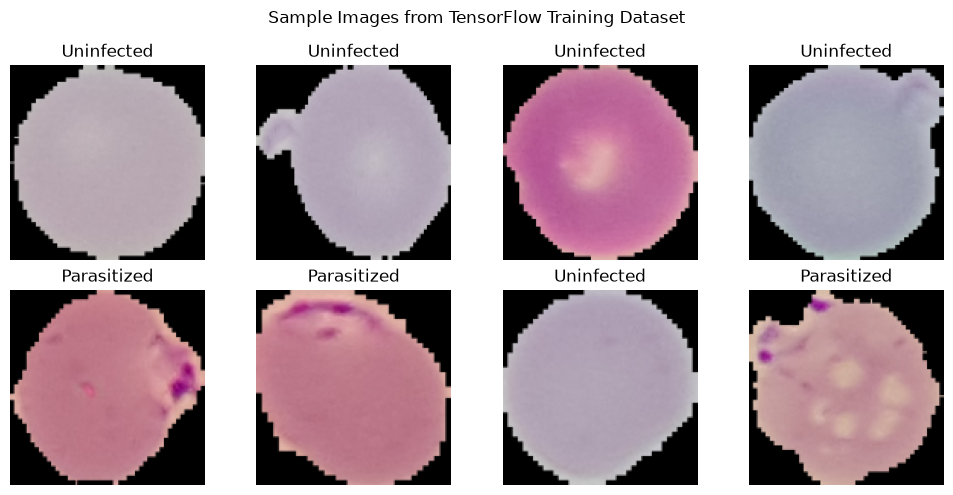

TensorFlow batch verification passed.


In [34]:

# Retrieve one training batch
images, batch_labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", batch_labels.shape)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))
print("Labels in batch:", np.unique(batch_labels.numpy()))

# Verify dimensions and normalized values
assert images.shape[1:] == (128, 128, 3)
assert float(tf.reduce_min(images)) >= 0
assert float(tf.reduce_max(images)) <= 1

# Display sample images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy())

    label = int(batch_labels[i].numpy())
    class_name = "Parasitized" if label == 1 else "Uninfected"

    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Sample Images from TensorFlow Training Dataset")
plt.tight_layout()
plt.show()

print("TensorFlow batch verification passed.")



The TensorFlow input pipeline successfully loaded the training images in batches of 32, with each image resized to 128 × 128 RGB and normalized to the 0–1 range. Visual inspection of sample images confirmed that the cell structures remained visible after preprocessing.

The training, validation, and testing datasets retain the group-aware partitions established earlier. These datasets are now ready for training-only image augmentation and baseline CNN development.



### Image Data Augmentation

To increase training data diversity and reduce overfitting, we will apply random rotations, horizontal and vertical flips, and limited zooming to the training images. These transformations will help the CNN learn features that are less sensitive to cell orientation and position.

Augmentation will be applied only during model training. Validation and testing images will not be augmented, allowing the models to be evaluated on unchanged images.


In [35]:

data_augmentation = keras.Sequential([
    keras.layers.RandomFlip(
        "horizontal_and_vertical",
        seed=SEED
    ),
    keras.layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect",
        seed=SEED
    ),
    keras.layers.RandomZoom(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect",
        seed=SEED
    )
], name="data_augmentation")

print("Image augmentation pipeline created.")


Image augmentation pipeline created.


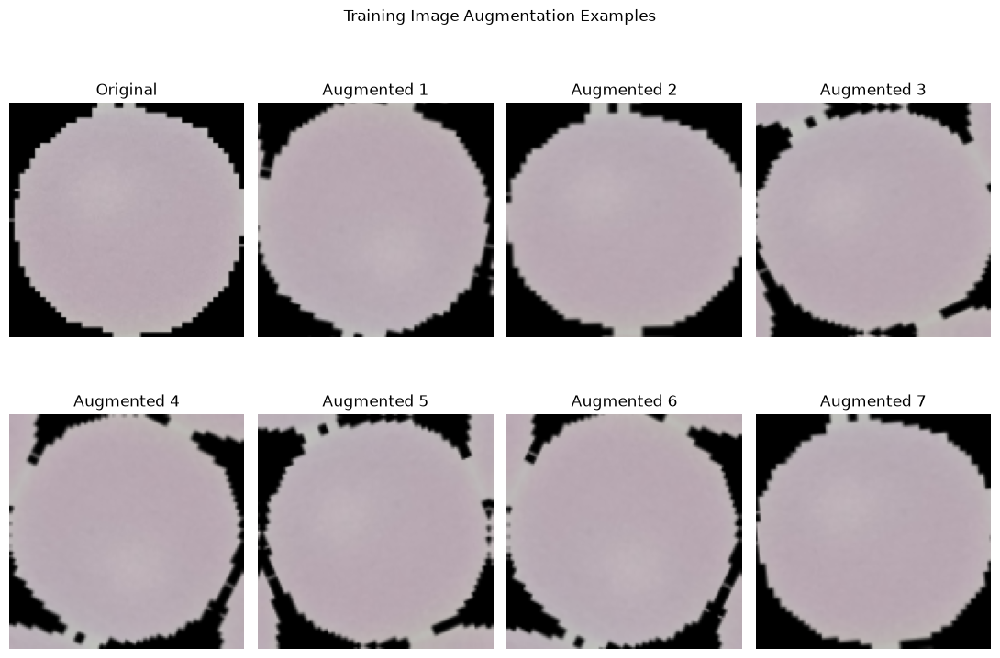

In [38]:
#Visualize the augmented images

# Select one image from the training batch
original_image = images[0]

fig, axes = plt.subplots(2, 4, figsize=(11,8))

# Original image
axes[0, 0].imshow(original_image.numpy())
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

# Generate seven augmented versions
for i, ax in enumerate(axes.flat[1:], start=1):
    augmented = data_augmentation(
        tf.expand_dims(original_image, axis=0),
        training=True
    )

    ax.imshow(tf.clip_by_value(augmented[0], 0, 1).numpy())
    ax.set_title(f"Augmented {i}")
    ax.axis("off")

plt.suptitle("Training Image Augmentation Examples")
plt.tight_layout()
plt.show()



The augmentation pipeline generated several variations of a training image using random flipping, rotation, and zooming. The zoom factor was reduced to 0.05 to limit excessive changes to the image. The main cell remained recognizable across the transformations, although some variations showed changes near the image boundaries. Augmentation will be applied only during training to increase image diversity and help reduce overfitting.



### Baseline CNN Architecture

We will develop a baseline Convolutional Neural Network (CNN) using TensorFlow/Keras to classify cell images as parasitized or uninfected. The model will use three convolutional blocks with 32, 64, and 128 filters, each followed by max pooling. A global average pooling layer and a fully connected layer with 128 neurons will be used before the final sigmoid output for binary classification.

The image augmentation pipeline developed earlier will be included in the model and activated only during training.

**This baseline architecture will serve as the reference for the optimization experiments.**


In [39]:
tf.keras.utils.set_random_seed(SEED)

baseline_model = keras.Sequential([
    # Input and training-only augmentation
    keras.layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    # Convolutional block 1
    keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    keras.layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
], name="malaria_baseline_cnn")

# Compile using the initial hyperparameters from the proposal
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.Recall(name="recall")
    ]
)

baseline_model.summary()


Model: "malaria_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)


The baseline CNN was created with three convolutional blocks containing 32, 64, and 128 filters, followed by global average pooling, a 128-neuron dense layer, and a sigmoid output. The model was compiled using the Adam optimizer with a learning rate of 0.001 and binary cross-entropy loss. Accuracy, recall, and AUC were selected to monitor model performance during training and validation.

The architecture and initial training settings will remain fixed for the baseline experiment, providing a consistent reference for subsequent optimization.



### Baseline CNN Training

The baseline CNN will be trained using the group-aware training dataset (19,255 images) and evaluated after each epoch using the validation dataset (4,160 images). The model will use the Adam optimizer with a learning rate of 0.001, a batch size of 32, and binary cross-entropy loss.

We will initially train for 15 epochs and monitor training and validation accuracy, recall, AUC, and loss to assess model convergence and identify possible overfitting or underfitting. Training time will also be recorded for comparison with optimized models.


In [40]:
%%script echo skipping
EPOCHS = 15

start_time = time.perf_counter()

tf.keras.utils.set_random_seed(SEED)
history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

training_time = time.perf_counter() - start_time

print(f"\nBaseline CNN training time: {training_time:.2f} seconds")


skipping


In [41]:
%%script echo skipping
# Save the baseline model and history in case the runtime disconnected

save_dir = Path("cnn_results")
model_path = save_dir / "malaria_baseline_cnn.keras"
history_path = save_dir / "malaria_baseline_history.json"

# Save trained CNN
baseline_model.save(str(model_path))

# Save epoch-by-epoch training metrics
with open(history_path, "w") as f:
    json.dump(
        {key: [float(x) for x in values]
         for key, values in history.history.items()},
        f,
        indent=2
    )

print("Model saved:", model_path.is_file())
print("History saved:", history_path.is_file())
print("Model size (MB):", round(model_path.stat().st_size / 1e6, 2))


skipping



The baseline CNN completed 15 training epochs in approximately 3 hours and 14 minutes (11,663.79 seconds). In the final epoch, the model achieved 95.83% training accuracy, 94.65% training recall, and a training AUC of 0.9861.

On the validation dataset, the model achieved 94.13% accuracy, 95.62% recall, and an AUC of 0.9830. These results indicate strong initial classification performance, particularly in identifying parasitized cells. However, the final validation loss (0.1862) was higher than the training loss (0.1296), suggesting a possible generalization gap.

The training history also shows that validation performance was better during some earlier epochs, which may indicate overfitting toward the end of training. We will examine the learning curves to better understand this behavior.



### Baseline CNN Learning Curves

To examine the model's learning behavior across the 15 epochs, we will plot the training and validation curves for loss, accuracy, recall, and ROC-AUC.

These plots will help us evaluate how quickly the model converged, whether its performance continued to improve, and whether there are signs of overfitting. Comparing the training and validation curves will also help identify opportunities for improvement during the CNN optimization stage.


In [42]:
%%script echo skipping
metrics = [
    ("loss", "Loss"),
    ("accuracy", "Accuracy"),
    ("recall", "Recall"),
    ("auc", "ROC-AUC")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (metric, title) in zip(axes.flat, metrics):
    ax.plot(history.history[metric], label="Training")
    ax.plot(history.history[f"val_{metric}"], label="Validation")

    ax.set_title(f"Baseline CNN - {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


skipping



The learning curves show that the baseline CNN improved rapidly during the first few epochs, with training accuracy, recall, and AUC increasing while training loss decreased. Validation performance also improved initially, indicating that the model was learning useful features for distinguishing parasitized and uninfected cells.

However, validation performance began to fluctuate toward the end of training. Validation loss reached its minimum of 0.1221 at Epoch 12 before increasing to 0.1862 at Epoch 15. Validation accuracy also decreased from its highest value of 96.18% at Epoch 12 to 94.13% in the final epoch. These trends suggest some overfitting during the later epochs.

Overall, the baseline achieved strong validation performance, particularly in recall and ROC-AUC. The results suggest that techniques such as early stopping and regularization could improve generalization during the optimization stage.



### Baseline CNN Validation Evaluation

After training the baseline CNN and examining its learning curves, we will perform a final evaluation using the validation dataset. The goal is to establish a reference for comparing the baseline with the optimized models developed in the next stage.

We will calculate accuracy, precision, recall, F1-score, and ROC-AUC, along with a confusion matrix. Recall is our primary evaluation metric because identifying parasitized cells is particularly important for this classification task. ROC-AUC will serve as the secondary metric.

The validation dataset will be used for this evaluation, while the test dataset will remain untouched until the final model is selected.


In [39]:
#%%script echo skipping
#Baseline CNN Validation Evaluation
baseline_model = tf.keras.models.load_model(
    f"baseline/baseline_cnn.keras"
)

# Generate predicted probabilities for validation images
val_probabilities = baseline_model.predict(val_ds, verbose=1).ravel()

# Convert probabilities to binary predictions
val_predictions = (val_probabilities >= 0.5).astype(int)

# True labels, in the same order as val_ds
val_true = np.concatenate([
    batch_labels.numpy().astype(int)
    for _, batch_labels in val_ds
])

assert len(val_true) == len(val_predictions), "Prediction count mismatch."

# Calculate classification metrics
baseline_results = {
    "Accuracy": accuracy_score(val_true, val_predictions),
    "Precision": precision_score(val_true, val_predictions, zero_division=0),
    "Recall": recall_score(val_true, val_predictions, zero_division=0),
    "F1-score": f1_score(val_true, val_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(val_true, val_probabilities)
}

print("Baseline CNN - Validation Results")
print("-" * 38)

for metric, value in baseline_results.items():
    print(f"{metric:<12}: {value:.4f}")

# Confusion matrix: rows = actual, columns = predicted
baseline_cm = confusion_matrix(
    val_true, val_predictions, labels=[0, 1]
)

print("\nConfusion Matrix:")
print(baseline_cm)


/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
2026-11-26 08:49:50.025193: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


130/130 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Baseline CNN - Validation Results
--------------------------------------
Accuracy    : 0.4995
Precision   : 0.4995
Recall      : 1.0000
F1-score    : 0.6662
ROC-AUC     : 0.4845

Confusion Matrix:
[[   0 2082]
 [   0 2078]]


2026-11-26 08:49:52.657994: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [44]:
%%script echo skipping
# Plot validation confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=["Uninfected", "Parasitized"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Baseline CNN - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


skipping


The confusion matrix shows that the baseline CNN correctly classified 1,929 uninfected cells and 1,987 parasitized cells out of 4,160 validation images. However, 153 uninfected cells were incorrectly classified as parasitized (false positives), while 91 parasitized cells were incorrectly classified as uninfected (false negatives).

The model achieved a recall of 95.62%, meaning it correctly identified most parasitized cells in the validation dataset. The relatively low number of false negatives is encouraging, since missing parasitized cells is a major concern in malaria detection. Overall, the confusion matrix supports the strong baseline performance observed in the evaluation metrics, while showing that there is still room to reduce classification errors during the optimization stage.


### Baseline CNN Handoff for Optimization

The baseline CNN training and validation evaluation are complete. The next stage will focus on optimizing CNN architecture and hyperparameters and comparing the optimized models against the baseline.

The finalized group-aware training, validation, and testing partitions must remain unchanged to ensure consistent comparisons. The TensorFlow datasets (`train_ds`, `val_ds`, and `test_ds`) are available for model training and evaluation.

The baseline model (`baseline_model`), training history (`history`), and validation results (`baseline_results`) provide the reference for comparison. The class labels are 0 for Uninfected and 1 for Parasitized.

The test dataset should only be used after selecting the final model based on validation performance.



### Saving the Final Dataset Partitions

To ensure reproducibility and a fair comparison between the baseline and optimized CNN models, we will save the finalized group-aware training, validation, and testing partitions into a single NumPy (`.npz`) file.

The file will contain the image paths and their corresponding labels for all three partitions. This allows the next team member to reuse exactly the same images without repeating the splitting procedure.

The test partition will remain reserved for the final evaluation of the selected model.


In [45]:
%%script echo skipping
#Save Final Dataset Partitions

partition_file = "/content/malaria_data_partitions.npz"

np.save_compressed(
    partition_file,
    train_paths=train_paths,
    train_labels=train_labels,
    val_paths=val_paths,
    val_labels=val_labels,
    test_paths=test_paths,
    test_labels=test_labels
)

print("Dataset partitions saved successfully.")
print("File:", partition_file)


skipping


In [46]:
%%script echo skipping
# Verify the saved dataset partitions

with np.load(partition_file, allow_pickle=False) as saved:
    print("Saved arrays:", saved.files)

    for split in ["train", "val", "test"]:
        paths = saved[f"{split}_paths"]
        labels = saved[f"{split}_labels"]

        print(f"\n{split.capitalize()} partition:")
        print("  Images:", len(paths))
        print("  Labels:", len(labels))
        print("  Class 0:", np.sum(labels == 0))
        print("  Class 1:", np.sum(labels == 1))

        assert len(paths) == len(labels)

print("\nPartition verification passed.")


skipping



The finalized group-aware partitions were saved into a compressed NumPy file containing the image paths and corresponding labels for training, validation, and testing. The saved partitions were verified to contain 19,255 training images, 4,160 validation images, and 4,143 testing images.

These partitions will be reused during CNN optimization to ensure that all models are trained and evaluated using consistent datasets. The original image files must remain accessible for loading the saved paths.


## Part 3: CNN Optimization and Evaluation

**Team Member: Noelle**

This section focuses on improving and evaluating the CNN model. It includes tuning hyperparameters, experimenting with dropout and regularization techniques, and comparing different model configurations. We will evaluate the baseline and optimized models using accuracy, precision, recall, F1-score, and confusion matrices to determine the impact of the improvements.

In order to minimize the runtime of the optimization experiment and not requiring potentially hundreds of complex models, each parameter will be tuned individually (for example, starting with learning rate and keeping the best value for learning rate, then tuning batch size with the best learning rate, number of filters with the best batch size and learning rate, and so on).

**Please note that all comments for this section are located in the full-team notebook. All code is identical across both notebooks with the exception of the ordering of some function definition cells and the syntax of file paths.**

In [47]:
# for Noelle's reference :

# Load finalized partitions
with np.load("malaria_data_partitions.npz", allow_pickle=False) as partitions:

    train_paths = partitions["train_paths"]
    train_labels = partitions["train_labels"]

    val_paths = partitions["val_paths"]
    val_labels = partitions["val_labels"]

    test_paths = partitions["test_paths"]
    test_labels = partitions["test_labels"]

print("Final dataset partitions loaded successfully.")


Final dataset partitions loaded successfully.


In [48]:
# Model-building function
def build_cnn(learning_rate, filters, dropout_rate, depth, batch_size):
    model = keras.Sequential()

    model.add(keras.layers.Input(shape=(128, 128, 3)))


    # Use a separate augmentation instance for each model
    model.add(keras.layers.RandomFlip(
        "horizontal_and_vertical", seed=SEED
    ))
    model.add(keras.layers.RandomRotation(
        0.08, fill_mode="reflect", seed=SEED
    ))
    model.add(keras.layers.RandomZoom(
        0.05, 0.05, fill_mode="reflect", seed=SEED
    ))


    # Convolutional blocks
    for i in range(depth):
        model.add(keras.layers.Conv2D(
            filters * (2 ** i),
            (3, 3),
            activation="relu",
            padding="same"
        ))
        model.add(keras.layers.MaxPooling2D((2, 2)))


    # Classification layers (outside the loop)
    model.add(keras.layers.GlobalAveragePooling2D())
    model.add(keras.layers.Dense(128, activation="relu"))


    if dropout_rate > 0:
        model.add(keras.layers.Dropout(dropout_rate))


    model.add(keras.layers.Dense(1, activation="sigmoid"))


    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Recall(name="recall")
        ]
    )


    model.batch_size = batch_size
    return model

In [49]:
# Define callbacks, including early stopping
def get_callbacks(model_name):
    return [
        ModelCheckpoint(
            filepath=f"cnn_results/{model_name}/{model_name}.keras",
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        ),

        BackupAndRestore(
            backup_dir=f"backups/{model_name}"
        ),

        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        )
    ]

In [50]:
# Define parameters to test
parameters = {
    "learning_rate": [0.001, 0.0001],
    "batch_size": [32, 64],
    "num_filters": [16, 32, 64],
    "depth": [2, 3, 4],
    "dropout": [0.2, 0.3, 0.4, 0.5]
}

In [51]:
# Function to run a model
def run_model(model_name, model, results_array, times):
  batch_size = model.batch_size
  train_batched = train_ds.unbatch().batch(batch_size)
  val_batched = val_ds.unbatch().batch(batch_size)

  start_time = time.perf_counter()

  tf.keras.utils.set_random_seed(SEED)
  history = model.fit(
    train_batched,
    validation_data=val_batched,
    epochs=EPOCHS,
    verbose=1,
    batch_size = batch_size,
    callbacks = get_callbacks(f"{model_name}"),
  )

  training_time = time.perf_counter() - start_time

  times[model_name] = training_time

  print(f"\nTraining time for {model_name}: {training_time:.2f} seconds")


  model.save(f"cnn_results/{model_name}/{model_name}.keras")
  with open(f"cnn_results/{model_name}/{model_name}_history.json", "w") as f:
    json.dump(
        {key: [float(x) for x in values]
         for key, values in history.history.items()},
        f,
        indent=2
    )
  results_array[f"{model_name}"] = history.history

  # Clean up for next model run
  del model
  tf.keras.backend.clear_session()
  return results_array

### Early Stopping
First, I will test the baseline model configuration including early stopping and backups as a control for the parameter-tuning experiment, where all models will incorporate early stopping.

In [52]:
tf.keras.utils.set_random_seed(SEED)

baseline_early_stopping = keras.Sequential([
    # Input and training-only augmentation
    keras.layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    # Convolutional block 1
    keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    keras.layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),
    keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
], name="malaria_baseline_cnn")

# Compile using the initial hyperparameters from the proposal
baseline_early_stopping.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.Recall(name="recall")
    ]
)

baseline_early_stopping.summary()


Model: "malaria_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
EPOCHS = 15

start_time = time.perf_counter()

tf.keras.utils.set_random_seed(SEED)
history = baseline_early_stopping.fit(
  train_ds,
  validation_data=val_ds,
  epochs=EPOCHS,
  verbose=1,
  callbacks = get_callbacks("baseline_early_stopping")
)

training_time = time.perf_counter() - start_time

print(f"\nTraining time for Baseline CNN with Early Stopping: {training_time:.2f} seconds")


Epoch 1/15


/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-11-24 14:40:05.565591: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


602/602 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5760 - auc: 0.5868 - loss: 9.6028 - recall: 0.5228
Epoch 1: val_loss improved from None to 1.43821, saving model to cnn_results/baseline_early_stopping/baseline_early_stopping.keras

Epoch 1: finished saving model to cnn_results/baseline_early_stopping/baseline_early_stopping.keras
602/602 ━━━━━━━━━━━━━━━━━━━━ 51s 82ms/step - accuracy: 0.5760 - auc: 0.5868 - loss: 9.6028 - recall: 0.5228 - val_accuracy: 0.5005 - val_auc: 0.5908 - val_loss: 1.4382 - val_recall: 0.0000e+00
Epoch 2/15
602/602 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5050 - auc: 0.5062 - loss: 3.6417 - recall: 0.4855
Epoch 2: val_loss did not improve from 1.43821
602/602 ━━━━━━━━━━━━━━━━━━━━ 48s 79ms/step - accuracy: 0.5050 - auc: 0.5062 - loss: 3.6417 - recall: 0.4855 - val_accuracy: 0.4995 - val_auc: 0.3907 - val_loss: 1.6702 - val_recall: 1.0000
Epoch 3/15
602/602 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.4993 - auc: 0.4993 - loss: 3.1854 - recall: 0.4

In [54]:
save_dir = Path("cnn_results/baseline_early_stopping")
model_path = save_dir / "baseline_early_stopping.keras"
history_path = save_dir / "baseline_early_stopping_history.json"

# Save trained CNN
baseline_early_stopping.save(str(model_path))

# Save epoch-by-epoch training metrics
with open(history_path, "w") as f:
    json.dump(
        {key: [float(x) for x in values]
         for key, values in history.history.items()},
        f,
        indent=2
    )

print("Model saved:", model_path.is_file())
print("History saved:", history_path.is_file())
print("Model size (MB):", round(model_path.stat().st_size / 1e6, 2))

Model saved: True
History saved: True
Model size (MB): 1.38


### Results for Model with Early Stopping

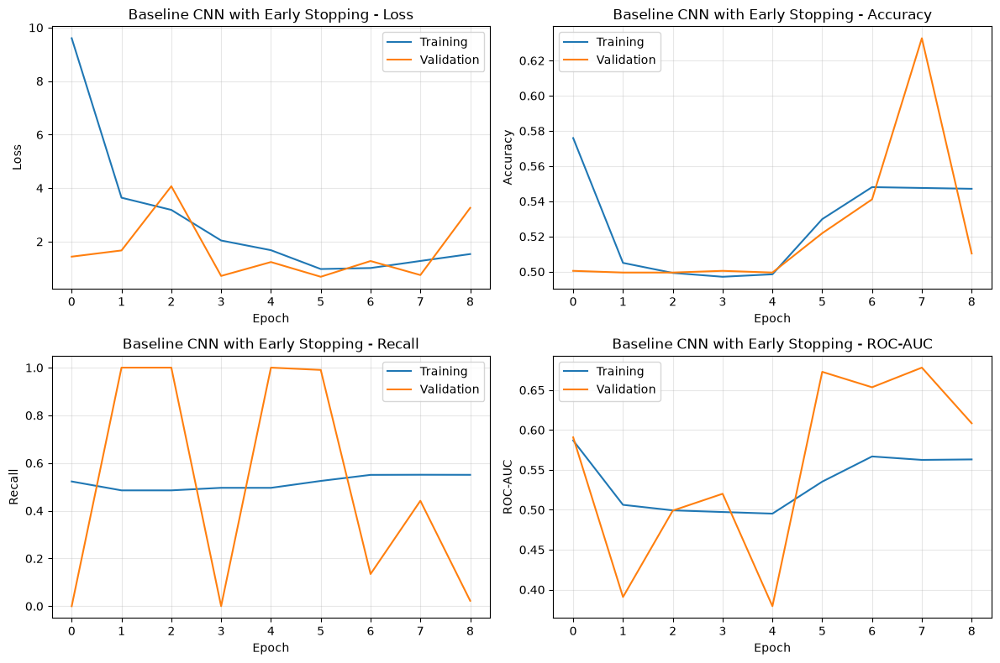

In [55]:
# Plot the curve of the loss
metrics = [
    ("loss", "Loss"),
    ("accuracy", "Accuracy"),
    ("recall", "Recall"),
    ("auc", "ROC-AUC")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (metric, title) in zip(axes.flat, metrics):
    ax.plot(history.history[metric], label="Training")
    ax.plot(history.history[f"val_{metric}"], label="Validation")

    ax.set_title(f"Baseline CNN with Early Stopping - {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Please disregard this plot and see the team notebook for the one used for analysis.

In [56]:
# Validation Set Metrics for Baseline with Early Stopping

# Generate predicted probabilities for validation images
val_probabilities = baseline_early_stopping.predict(val_ds, verbose=1).ravel()

# Convert probabilities to binary predictions
val_predictions = (val_probabilities >= 0.5).astype(int)

# True labels, in the same order as val_ds
val_true = np.concatenate([
    batch_labels.numpy().astype(int)
    for _, batch_labels in val_ds
])

assert len(val_true) == len(val_predictions), "Prediction count mismatch."

# Calculate classification metrics
baseline_early_stopping_results = {
    "Accuracy": accuracy_score(val_true, val_predictions),
    "Precision": precision_score(val_true, val_predictions, zero_division=0),
    "Recall": recall_score(val_true, val_predictions, zero_division=0),
    "F1-score": f1_score(val_true, val_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(val_true, val_probabilities)
}

print("Baseline CNN - Validation Results")
print("-" * 38)

for metric, value in baseline_early_stopping_results.items():
    print(f"{metric:<12}: {value:.4f}")

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(
    val_true, val_predictions, labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)


130/130 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
Baseline CNN - Validation Results
--------------------------------------
Accuracy    : 0.5219
Precision   : 0.5111
Recall      : 0.9904
F1-score    : 0.6742
ROC-AUC     : 0.6731

Confusion Matrix:
[[ 113 1969]
 [  20 2058]]


2026-11-24 14:47:22.649352: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


NameError: name 'cm' is not defined

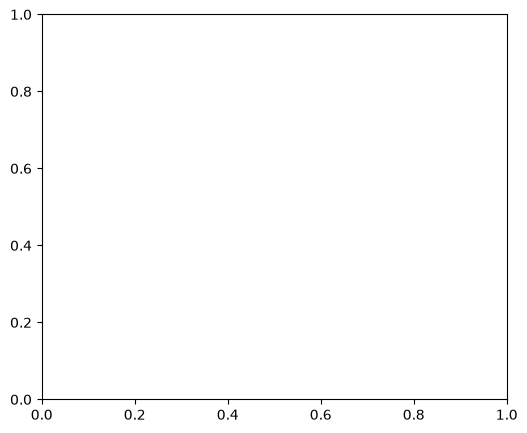

In [36]:
# Confusion Matrix for Baseline with Early Stopping
fig, ax = plt.subplots(figsize=(6, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Uninfected", "Parasitized"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Baseline CNN with Early Stopping - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

Please see the full-team notebook to view this plot.

### Build Models for Tuning Hyperparameters

In [65]:
tf.keras.utils.set_random_seed(SEED)

models = {}
for lr in parameters["learning_rate"]:
  for f in parameters["num_filters"]:
    for dr in parameters["dropout"]:
      for d in parameters["depth"]:
        for b in parameters["batch_size"]:
          models[f"model_{lr}_{f}_{dr}_{d}_{b}"] = build_cnn(
              learning_rate = lr,
              filters = f,
              dropout_rate = dr,
              depth = d,
              batch_size = b
          )
print(next(iter(models.items())))

('model_0.001_16_0.2_2_32', <Sequential name=sequential, built=True>)


### Run Models

In [ ]:
results = {}
times = {}
tf.keras.utils.set_random_seed(SEED)

for model_name, model in models.items():
  if model_name in os.listdir("cnn_results"):
        print(f"Skipping already fitted model: {model_name}")
        continue
  print(f"Fitting model {model_name}")
  run_model(model_name, model, results, times)

Fitting model model_0.001_16_0.2_2_32
Epoch 1/15
    602/Unknown 39s 56ms/step - accuracy: 0.6064 - auc: 0.6525 - loss: 0.6590 - recall: 0.5548

2026-11-24 17:50:46.706745: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 11374971087785654841
2026-11-24 17:50:46.706770: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 1888651195091713241
2026-11-24 17:50:46.706775: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 5400864688837485355
2026-11-24 17:50:46.706783: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 3841447525695988841
2026-11-24 17:50:46.706787: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 17350080090092881211
2026-11-24 17:50:46.706794: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 17722746693076895881
2026-11-24 17:50:46.706802: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv 


Epoch 1: val_loss improved from None to 0.65026, saving model to cnn_results/model_0.001_16_0.2_2_32/model_0.001_16_0.2_2_32.keras

Epoch 1: finished saving model to cnn_results/model_0.001_16_0.2_2_32/model_0.001_16_0.2_2_32.keras
602/602 ━━━━━━━━━━━━━━━━━━━━ 43s 62ms/step - accuracy: 0.6064 - auc: 0.6525 - loss: 0.6590 - recall: 0.5548 - val_accuracy: 0.6587 - val_auc: 0.7267 - val_loss: 0.6503 - val_recall: 0.5308
Epoch 2/15


2026-11-24 17:50:49.984744: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 978597501119957288
2026-11-24 17:50:49.984763: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 17451535735438954805
2026-11-24 17:50:49.984767: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 11658067234789397215
2026-11-24 17:50:49.984770: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 5546975106510257569
2026-11-24 17:50:49.984774: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 14746199542597668373
2026-11-24 17:50:49.984777: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 8500404600779978695
2026-11-24 17:50:49.984784: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv i

602/602 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.6537 - auc: 0.7144 - loss: 0.6358 - recall: 0.5557

2026-11-24 17:51:21.842376: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 15054723570227314955
2026-11-24 17:51:21.842403: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 6255798409690807851
2026-11-24 17:51:21.842452: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 17350080090092881211
2026-11-24 17:51:21.842456: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 1379793206818326231
2026-11-24 17:51:21.842465: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 17722746693076895881
2026-11-24 17:51:21.842479: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 15828175892811172159
2026-11-24 17:51:21.842484: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv

... (4,393 outputs left out)

2026-11-25 13:28:04.824220: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 1523717170593644623
2026-11-25 13:28:04.825470: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 9754095334035783953
2026-11-25 13:28:04.825488: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 8733515648760872362
2026-11-25 13:28:04.825491: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 16753422005990720075
2026-11-25 13:28:04.825498: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 6909011813059445786
2026-11-25 13:28:04.825504: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 3238319344848323994
2026-11-25 13:28:04.825505: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv it


Epoch 6: val_loss did not improve from 0.67897
301/301 ━━━━━━━━━━━━━━━━━━━━ 146s 483ms/step - accuracy: 0.5778 - auc: 0.6046 - loss: 1.7814 - recall: 0.5935 - val_accuracy: 0.6849 - val_auc: 0.7359 - val_loss: 1.0723 - val_recall: 0.8571
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


2026-11-25 13:28:10.610466: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 16375769592171153523
2026-11-25 13:28:10.610500: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 13139721127201865743
2026-11-25 13:28:10.610504: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 818921464907719431
2026-11-25 13:28:10.610507: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 11668386589085983885
2026-11-25 13:28:10.610534: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 9595702720446705682
2026-11-25 13:28:10.610538: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv item cancelled. Key hash: 11395738919506895116
2026-11-25 13:28:10.610541: I tensorflow/core/framework/local_rendezvous.cc:424] Local rendezvous recv 


Training time for model_0.0001_64_0.5_4_64: 1015.97 seconds


### Model Evaluation Functions

In [67]:
# Define functions for evaluating models
def plot_curves(history, model_name):
  metrics = [
      ("loss", "Loss"),
      ("accuracy", "Accuracy"),
      ("recall", "Recall"),
      ("auc", "ROC-AUC")
  ]

  fig, axes = plt.subplots(2, 2, figsize=(12, 8))

  for ax, (metric, title) in zip(axes.flat, metrics):
      ax.plot(history[metric], label="Training")
      ax.plot(history[f"val_{metric}"], label="Validation")

      ax.set_title(f"{model_name} CNN - {title}")
      ax.set_xlabel("Epoch")
      ax.set_ylabel(title)
      ax.legend()
      ax.grid(True, alpha=0.3)

  plt.tight_layout()
  plt.show()

In [68]:
# Validation evaluation
def val_eval(model, model_name):
  val_probabilities = model.predict(val_ds, verbose=1).ravel()

  val_predictions = (val_probabilities >= 0.5).astype(int)

  val_true = np.concatenate([
      batch_labels.numpy().astype(int)
      for _, batch_labels in val_ds
  ])

  assert len(val_true) == len(val_predictions), "Prediction count mismatch."

  model_results = {
      "Accuracy": accuracy_score(val_true, val_predictions),
      "Precision": precision_score(val_true, val_predictions, zero_division=0),
      "Recall": recall_score(val_true, val_predictions, zero_division=0),
      "F1-score": f1_score(val_true, val_predictions, zero_division=0),
      "ROC-AUC": roc_auc_score(val_true, val_probabilities)
  }

  print(f"{model_name} CNN - Validation Results")
  print("-" * 38)

  for metric, value in model_results.items():
      print(f"{metric:<12}: {value:.4f}")

  cm = confusion_matrix(
      val_true, val_predictions, labels=[0, 1]
  )

  print("\nConfusion Matrix:")
  print(cm)

  return model_results, cm

In [69]:
# Display confusion matrix
def display_confusion_matrix(cm):
  fig, ax = plt.subplots(figsize=(6, 5))

  display = ConfusionMatrixDisplay(
      confusion_matrix = cm,
      display_labels = ["Uninfected", "Parasitized"]
  )

  display.plot(
      ax=ax,
      cmap="Blues",
      values_format="d",
      colorbar=False
  )

  ax.set_title("Baseline CNN - Validation Confusion Matrix")
  plt.tight_layout()
  plt.show()

### Evaluate All Models on the Validation Set

In [70]:
metrics = {}
cms = {}
losses = []

for model_name in os.listdir("cnn_results/"):
    # Compare validation losses
    with open(f"cnn_results/{model_name}/{model_name}_history.json", "r") as f:
        print(model_name)
        history = json.load(f)
        
        losses.append({
            "model": model_name,
            "min_val_loss": min(history["val_loss"]),
            "best_epoch": history["val_loss"].index(min(history["val_loss"])) + 1,
            "final_val_loss": history["val_loss"][-1],
            "min_val_accuracy": max(history["val_accuracy"]),
            "best_accuracy_epoch": history["val_accuracy"].index(
                max(history["val_accuracy"])
            ) + 1
        }) 

    # Use val_eval function to get metrics
    model = tf.keras.models.load_model(
        f"cnn_results/{model_name}/{model_name}.keras"
    )
    model_metrics, cm = val_eval(model, model_name)
    metrics[f"{model_name}"] = model_metrics
    cms[f"{model_name}"] = cm

model_0.001_64_0.2_2_64
130/130 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step
model_0.001_64_0.2_2_64 CNN - Validation Results
--------------------------------------
Accuracy    : 0.6656
Precision   : 0.6588
Recall      : 0.6858
F1-score    : 0.6720
ROC-AUC     : 0.7187

Confusion Matrix:
[[1344  738]
 [ 653 1425]]
model_0.001_64_0.4_4_32
130/130 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step
model_0.001_64_0.4_4_32 CNN - Validation Results
--------------------------------------
Accuracy    : 0.6010
Precision   : 0.8426
Recall      : 0.2474
F1-score    : 0.3824
ROC-AUC     : 0.8934

Confusion Matrix:
[[1986   96]
 [1564  514]]
model_0.0001_16_0.5_3_32
130/130 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
model_0.0001_16_0.5_3_32 CNN - Validation Results
--------------------------------------
Accuracy    : 0.6548
Precision   : 0.7232
Recall      : 0.5005
F1-score    : 0.5916
ROC-AUC     : 0.7450

Confusion Matrix:
[[1684  398]
 [1038 1040]]
model_0.0001_32_0.2_2_32
130/130 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step
model_0.0001_32_

In [71]:
best_models = {}

for metric in ["Recall", "ROC-AUC", "Accuracy", "Precision", "F1-score"]:

    best_model = max(
        metrics,
        key=lambda model: metrics[model][metric]
    )

    best_models[metric] = {
        "Model": best_model,
        "Score": metrics[best_model][metric]
    }

    print(f"Model with Top {metric}:")
    print(f"{best_model}, {metric} = {metrics[best_model][metric]:.4f}")

Model with Top Recall:
model_0.001_64_0.5_3_64, Recall = 1.0000
Model with Top ROC-AUC:
model_0.001_16_0.3_4_32, ROC-AUC = 0.9846
Model with Top Accuracy:
model_0.001_16_0.3_4_32, Accuracy = 0.9543
Model with Top Precision:
model_0.001_64_0.2_2_32, Precision = 0.9861
Model with Top F1-score:
model_0.001_16_0.3_4_32, F1-score = 0.9536


In [74]:
for key, value in metrics["model_0.001_16_0.3_4_32"].items():
    print(f"{key}: {value}")

Accuracy: 0.9543269230769231
Precision: 0.9677898909811695
Recall: 0.9398460057747835
F1-score: 0.95361328125
ROC-AUC: 0.9845535406375191


### Plot Curves and Confusion Matrix

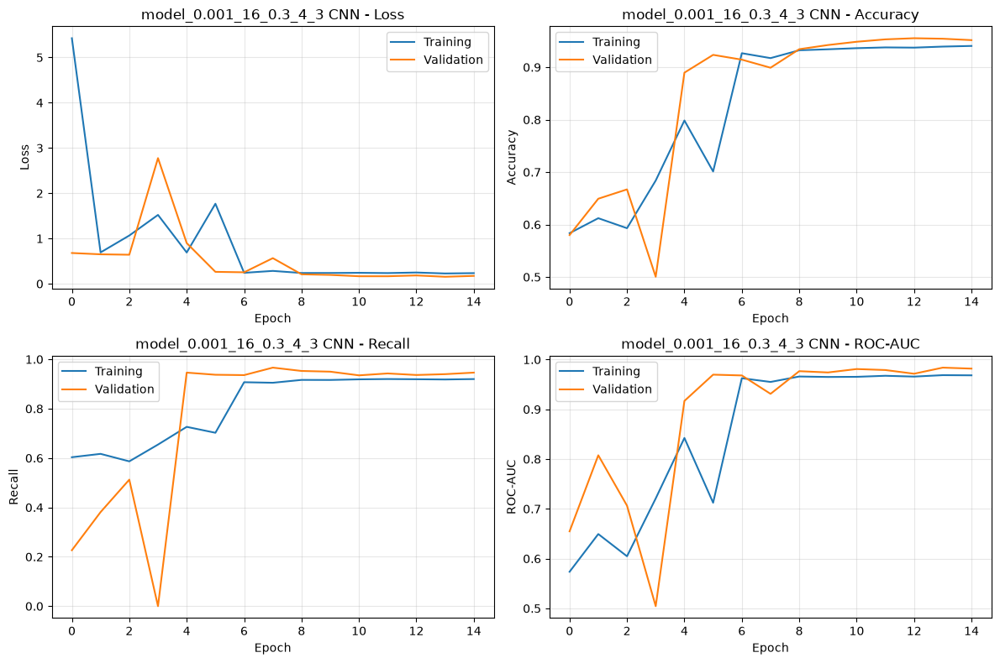

In [79]:
with open("cnn_results/model_0.001_16_0.3_4_32/model_0.001_16_0.3_4_32_history.json", "r") as f:
    history_best = json.load(f)

plot_curves(history_best, "model_0.001_16_0.3_4_3")

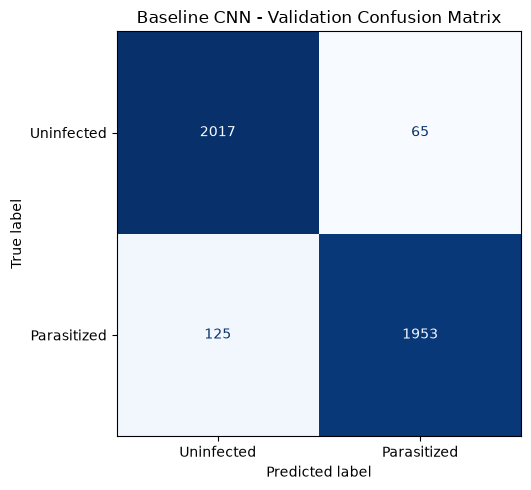

In [80]:
display_confusion_matrix(cms["model_0.001_16_0.3_4_32"])

### Test-Set Evaluation

In [81]:
# Make test-set predictions based on best model
model = tf.keras.models.load_model(
    f"cnn_results/model_0.001_16_0.3_4_32/model_0.001_16_0.3_4_32.keras"
)

test_probabilities = model.predict(test_ds, verbose=1).ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

test_true = np.concatenate([
    batch_labels.numpy().astype(int)
    for _, batch_labels in test_ds
])

assert len(test_true) == len(test_predictions), "Prediction count mismatch."

model_results = {
    "Accuracy": accuracy_score(test_true, test_predictions),
    "Precision": precision_score(test_true, test_predictions, zero_division=0),
    "Recall": recall_score(test_true, test_predictions, zero_division=0),
    "F1-score": f1_score(test_true, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(test_true, test_probabilities)
}

print("Test Results for CNN with learning rate = 0.001, batch size = 32, depth = 4, dropout = 0.2, and filters = 16")
print("-" * 38)

for metric, value in model_results.items():
    print(f"{metric:<12}: {value:.4f}")

cm = confusion_matrix(
    test_true, test_predictions, labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step
Test Results for CNN with learning rate = 0.001, batch size = 32, depth = 4, dropout = 0.2, and filters = 16
--------------------------------------
Accuracy    : 0.9496
Precision   : 0.9785
Recall      : 0.9196
F1-score    : 0.9481
ROC-AUC     : 0.9765

Confusion Matrix:
[[2024   42]
 [ 167 1910]]


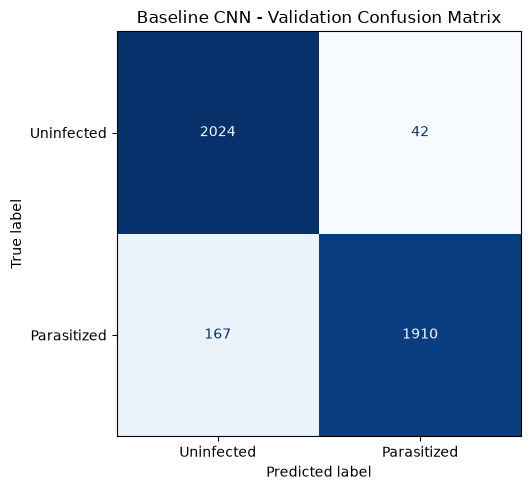

In [82]:
# Confusion matrix
display_confusion_matrix(cm)